# Demo 3: Persistence of the goal encoding (temporal and obstacle)

**Question.** Demo 2 read the next sub-goal out of the goal heads at the pivot, *before* the model writes it. Does that
encoding stick around while the model implements the sub-goal, and does it go away once the sub-goal is done?
And at the behavioural level, if we force a bad start onto the line, does the model keep pursuing the sub-goal
and work around the obstacle?

**Paper.** §3.4 (`Text/persistance.tex`, `fig:temporal-retention`) and App. `app:persistence:temporal`
(`fig:retention-control`); App. `app:persistence:obstacle` (`tab:obstacle-models`).

**What you'll see.**
1. **Temporal persistence** on one condition. A 4-sub-task Python function, prefilled up to `b =`. The model writes
   `b` and then, unprompted, `c`, `d` and the `return`. At every generated token we take the goal heads' summed
   write (the *goal encoding*) and compare it with the encoding at the `b =` pivot. It stays high while `b` is being
   written and drops when the model moves on to `c`. The encoding at the `c =` and `d =` pivots does the
   opposite. The same analysis with 122 random **control** heads gives a much flatter picture.
2. The pooled version over the cached paper run (goal vs control, `fig:retention-control`).
3. **Obstacle persistence**: one sub-task, the line `b =` force-started with prefixes of three difficulty levels,
   the model's continuation, and the Claude judge's verdict (ADAPTED / SUCCUMBED / ESCAPED / BROKEN).

Needs one 80 GB GPU (Qwen2.5-Coder-32B-Instruct in bf16). The executed outputs are saved in this file.

**From the talk** (figures from `Goals_lab_talk.pptx`):

![Temporal persistence: the encoding persists through the implementation, then is released (§3.4, Fig. 3).](figures/03_temporal_persistence.png)

*Temporal persistence: the encoding persists through the implementation, then is released (§3.4, Fig. 3).*

![Obstacle persistence: plant a prefill and see whether the model recovers (App. K.2).](figures/03_obstacle_setup.png)

*Obstacle persistence: plant a prefill and see whether the model recovers (App. K.2).*

In [1]:
# repo root = first parent dir that contains src/
import os, sys
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)
print('repo root:', _d)

# no progress bars: keeps tqdm / HF widget outputs out of the saved notebook
os.environ['TQDM_DISABLE'] = '1'
import functools, tqdm.std, tqdm.notebook, transformers, huggingface_hub
for _c in (tqdm.std.tqdm, tqdm.notebook.tqdm):   # tqdm.notebook ignores TQDM_DISABLE, so force disable=True
    _c.__init__ = functools.partialmethod(_c.__init__, disable=True)
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.disable_progress_bars()

repo root: /disk/u/arnab/Codes/Projects/goals


## Config
Defaults are the paper's (`src/goals/temporal_persistence.py`: 122 goal heads, 96-token rollout; control = 122 random
heads from layers 32-63, disjoint from the goal heads, `CONTROL_SEED = 7` of
`scripts/evaluation/temporal_persistence_eval.py`).

**Why this condition.** The context `str | is_alnum, vowel_count, word_count, count_digits` probed at its second
sub-task (`vowel_count`, written as `b`) is in both cached runs (goal and control), its implementation is 16 tokens
long (inside the 10-40-token band the paper figure uses), and after `b` the model writes two more sub-tasks
on its own, so we can watch the encoding switch. In the cached run its goal-head retention is among the highest
of the Python conditions that also have a control record. (That is a selection effect; the pooled curve in §4 is the
unbiased picture.)

**Why this obstacle.** `list[int] / total_sum` ("the sum of all values"). Under the hard prefix `" - 1 +"` (a
wrong-op fragment) the paper run got ADAPTED: the model writes `- 1 + sum(nums) + 1`, cancelling the forced `- 1`.
The same predicate also has a SUCCUMBED hard case, so one table shows both outcomes.

In [2]:
CUDA         = '7'
MODEL        = 'Qwen/Qwen2.5-Coder-32B-Instruct'
CTX_KEY      = 'str|python|is_alnum,vowel_count,word_count,count_digits'   # one context of the cached run
TARGET_POS   = 1          # probe the 2nd sub-task (b); the 1st (a) is the prefilled seed
CONTROL_SEED = 7          # scripts/evaluation/temporal_persistence_eval.py
OBST_DT, OBST_PID = 'list[int]', 'total_sum'
SEED         = 1123
OUT_DIR      = '/tmp/claude-1102/-disk-u-arnab-Codes-Projects-goals/84e6baf5-bb07-4894-8d4b-fe628154ae4f/scratchpad/demo_out'  # nothing is written to results/

os.environ['CUDA_VISIBLE_DEVICES'] = CUDA
os.makedirs(OUT_DIR, exist_ok=True)

## Load the model, the goal heads and the control heads

In [3]:
import glob, json, random, torch
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.markup import escape

from src.models import ModelandTokenizer
from src.utils import experiment_utils
import src.nrgs.data as D
from src.goals import temporal_persistence as TP
from scripts.evaluation.ablation_common import random_heads_like
sys.path.insert(0, 'notebooks/fig_n_table_generators')
import figstyle as F; F.set_style()

console = Console(width=130, highlight=False)
torch.set_grad_enabled(False)
experiment_utils.set_seed(SEED)

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='eager')
SLUG = MODEL.split('/')[-1]
goal_heads = TP.load_goal_heads(mt, SLUG)
ctrl_heads = random_heads_like(ablated=goal_heads, from_layer=mt.n_layer // 2, n_layer=mt.n_layer,
                               n_heads=mt.n_heads, exclude=goal_heads, rng=random.Random(CONTROL_SEED))
print(f'goal heads: {len(goal_heads)} (layers {min(l for l,_ in goal_heads)}-{max(l for l,_ in goal_heads)}) | '
      f'control heads: {len(ctrl_heads)} (layers {min(l for l,_ in ctrl_heads)}-{max(l for l,_ in ctrl_heads)}), '
      f'overlap {len(set(goal_heads) & set(ctrl_heads))}')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


goal heads: 122 (layers 28-55) | control heads: 122 (layers 33-63), overlap 0


# Part A: temporal persistence

## 1. The frontier-prefill probe
The eval script samples contexts with `multi_predicate_setups` (3-4 sub-tasks, seed 1123). We rebuild the same
sample and pick our context. `build_probe_prompt` lists *all* sub-tasks in the instruction, prefills the ones before
the target as full lines, and stops at the target's `=`. That `=` is the **pivot**.

In [4]:
setups = D.multi_predicate_setups('str', n_conditions=list(TP.N_COND), n_samples=256, seed=SEED,
                                  naming='letters', src_lang='python', dst_lang='python')
inst = next(i for i in setups if TP.context_key(i) == CTX_KEY)
preds = inst._preds_for(inst.src_frontier)
prompt, tv = TP.build_probe_prompt(mt, inst, preds, TARGET_POS)

t = Table(title=escape(CTX_KEY))
t.add_column('var'); t.add_column('sub-task'); t.add_column('status')
for k, p in enumerate(preds):
    st = 'prefilled' if k < TARGET_POS else ('[bold magenta]TARGET (probed at its `=`)[/]' if k == TARGET_POS else 'later: model writes it unprompted')
    t.add_row(TP._letter(k), escape(p.description), st)
console.print(t)
print(prompt)

                  str|python|is_alnum,vowel_count,word_count,count_digits                   
┏━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ var ┃ sub-task                                       ┃ status                            ┃
┡━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ a   │ whether every character is a letter or a digit │ prefilled                         │
│ b   │ the number of vowels                           │ TARGET (probed at its `=`)        │
│ c   │ the number of whitespace-separated words       │ later: model writes it unprompted │
│ d   │ the number of digit characters                 │ later: model writes it unprompted │
└─────┴────────────────────────────────────────────────┴───────────────────────────────────┘

<|im_start|>system
You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just the code, no need to comment or explain.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `func` which, given a string `s`, computes in sequential order:
(1) whether every character is a letter or a digit
(2) the number of vowels
(3) the number of whitespace-separated words
(4) the number of digit characters
<|im_end|>
<|im_start|>assistant
<code>
def func(s: str):
    a = s.isalnum()
    b =


## 2. Roll out, and find the implementation span
Greedy, 96 tokens (`TP.rollout_probe`). The paper segments the target's implementation with a Claude oracle
(`TP.oracle_value_segment`; it handles multi-line C++ blocks) and maps it to tokens (`TP.locate_value`). We use the
same calls. The later lines (`c =`, `d =`) are single Python lines, so we locate them directly.

In [5]:
full_text = TP.rollout_probe(mt, prompt)
gen = full_text[len(prompt):]
console.print('[dim]' + escape(prompt.split('<code>\n')[-1]) + '[/dim][bold green]' + escape(gen) + '[/bold green]')

offs = TP._offsets(mt, full_text)
P = TP.prompt_boundary(mt, prompt, full_text)            # first generated token; the `b =` pivot is P-1
code_prefix = prompt.split('<code>\n', 1)[-1]
seg = TP.oracle_value_segment(code_prefix, tv, preds[TARGET_POS].description, gen)
eq_tok, impl = TP.locate_value(offs, full_text, len(prompt), P, seg)
print(f'\noracle segment for `{tv}`: {seg!r}  ->  {len(impl)} impl tokens [{impl[0]}..{impl[-1]}], pivot token {eq_tok}')

# later sub-tasks: their own `=` pivot and their single-line implementation
later = {}
for k in range(TARGET_POS + 1, len(preds)):
    v = TP._letter(k)
    c0 = full_text.find(f'\n    {v} =', len(prompt))
    if c0 < 0:
        continue
    eq_c = full_text.index('=', c0)
    line_end = full_text.find('\n', eq_c); line_end = len(full_text) if line_end < 0 else line_end
    eqt = next(i for i, (a, b) in enumerate(offs) if a <= eq_c < b)
    later[v] = dict(eq=eqt, impl=TP._toks_in(offs, eq_c + 1, line_end), desc=preds[k].description)
for v, d in later.items():
    print(f'`{v} =` pivot token {d["eq"]}, impl tokens [{d["impl"][0]}..{d["impl"][-1]}]: {d["desc"]}')

def func(s: str):
    a = s.isalnum()
    b = sum(1 for char in s if char.lower() in 'aeiou')
    c = len(s.split())
    d = sum(1 for char in s if char.isdigit())
    return a, b, c, d
</code>


oracle segment for `b`: "sum(1 for char in s if char.lower() in 'aeiou')"  ->  16 impl tokens [128..143], pivot token 127
`c =` pivot token 146, impl tokens [147..150]: the number of whitespace-separated words
`d =` pivot token 153, impl tokens [154..164]: the number of digit characters


## 3. The goal encoding at every generated token
`TP.goal_encoding` = the heads' summed residual write (o_proj of the selected heads) at the given positions, one
forward pass over `full_text`. We compute it from the `b =` pivot to the last generated token, with the goal heads
and with the control heads, and plot the cosine with each sub-task's pivot encoding (`b =`, `c =`, `d =`).

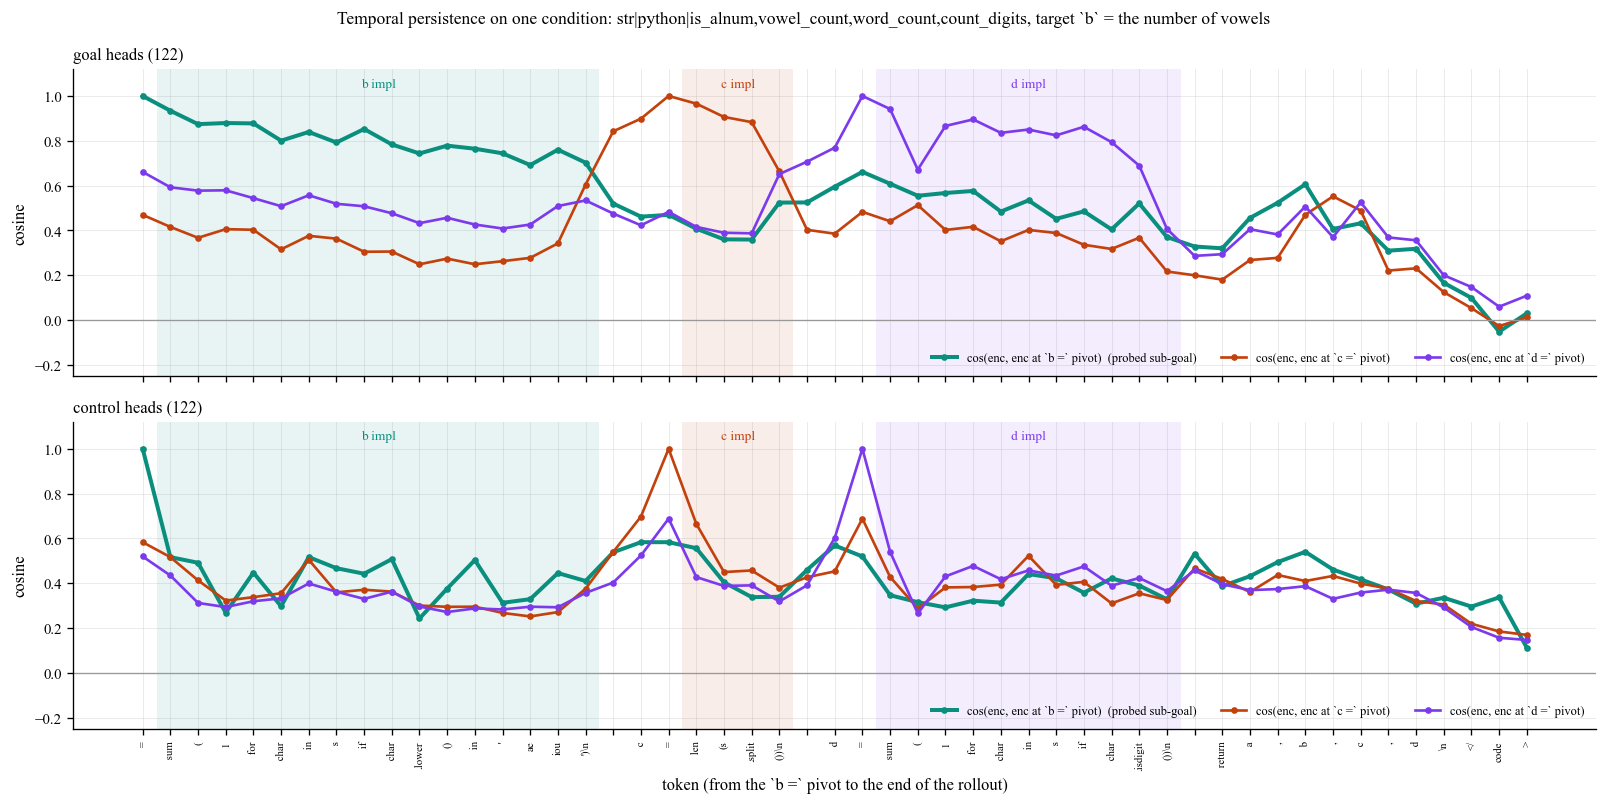

In [6]:
L = len(offs)
positions = list(range(eq_tok, L))
enc = {'goal': TP.goal_encoding(mt, full_text, positions, goal_heads),
       'control': TP.goal_encoding(mt, full_text, positions, ctrl_heads)}
idx = {p: i for i, p in enumerate(positions)}
pivots = {tv: eq_tok, **{v: d['eq'] for v, d in later.items()}}
spans = {tv: impl, **{v: d['impl'] for v, d in later.items()}}

def cos_to(E, p):
    U = E / E.norm(dim=-1, keepdim=True)
    return (U @ U[idx[p]]).numpy()

colors = {tv: F.TP_TEAL, **dict(zip(later, [F.TP_ORANGE, '#7c3aed']))}
fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.8), sharex=True, sharey=True)
xs = np.arange(len(positions))
toks = [mt.tokenizer.decode([i]) for i in TP.prepare_input(prompts=full_text, tokenizer=mt)['input_ids'][0].tolist()]
for ax, (name, E) in zip(axes, enc.items()):
    for v, sp in spans.items():
        ax.axvspan(idx[sp[0]] - .5, idx[sp[-1]] + .5, color=colors[v], alpha=.09, lw=0)
        ax.text((idx[sp[0]] + idx[sp[-1]]) / 2, 1.04, f'{v} impl', ha='center', fontsize=8, color=colors[v])
    for v, p in pivots.items():
        lw = 2.4 if v == tv else 1.6
        ax.plot(xs, cos_to(E, p), color=colors[v], lw=lw, marker='o', ms=3,
                label=f'cos(enc, enc at `{v} =` pivot)' + ('  (probed sub-goal)' if v == tv else ''))
    ax.axhline(0, color='#999', lw=.8)
    ax.set_ylabel('cosine'); ax.set_ylim(-0.25, 1.12)
    ax.set_title(f'{name} heads ({len(goal_heads) if name == "goal" else len(ctrl_heads)})', fontsize=10, loc='left')
    ax.legend(fontsize=7.5, frameon=False, loc='lower right', ncol=3)
axes[-1].set_xticks(xs); axes[-1].set_xticklabels([repr(toks[p])[1:-1] for p in positions], rotation=90, fontsize=6.5)
axes[-1].set_xlabel('token (from the `b =` pivot to the end of the rollout)')
fig.suptitle(f'Temporal persistence on one condition: {escape(CTX_KEY)}, target `{tv}` = {preds[TARGET_POS].description}', fontsize=10.5)
fig.tight_layout(); plt.show()

How to read the plot. In the goal-head panel the teal curve (similarity to the `b =` pivot) stays at about
0.7-0.9 over the whole `b impl` region. It drops to about 0.4-0.5 once the line is done. The `c =` curve (orange)
starts to climb at the newline that ends `b`, before the model has written `c`, and peaks over `c`'s
implementation. The `d =` curve (purple) does the same one line later. The encoding tracks *which sub-goal is
being implemented* and hands over at the line boundary. With the control heads every curve spikes only at its own
pivot token (a vector always matches itself) and then sits at about 0.3-0.5 everywhere: nothing persists or hands
over. The table averages each curve over each implementation span (bold = the sub-goal's own span).

In [7]:
t = Table(title='mean cos(enc at token, enc at pivot) over each implementation span (rows: pivot, cols: span)')
t.add_column('heads'); t.add_column('pivot')
for v in spans: t.add_column(f'{v} impl', justify='right')
for name, E in enc.items():
    for v, p in pivots.items():
        c = cos_to(E, p)
        cells_ = []
        for w, sp in spans.items():
            m = float(np.mean([c[idx[q]] for q in sp]))
            cells_.append(f'[bold]{m:.2f}[/]' if w == v else f'{m:.2f}')
        t.add_row(name, f'`{v} =`', *cells_)
console.print(t)

mean cos(enc at token, enc at pivot) over each
implementation span (rows: pivot, cols: span) 
┏━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ heads   ┃ pivot ┃ b impl ┃ c impl ┃ d impl ┃
┡━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ goal    │ `b =` │   0.80 │   0.41 │   0.51 │
│ goal    │ `c =` │   0.34 │   0.85 │   0.38 │
│ goal    │ `d =` │   0.50 │   0.46 │   0.79 │
│ control │ `b =` │   0.41 │   0.41 │   0.36 │
│ control │ `c =` │   0.35 │   0.49 │   0.38 │
│ control │ `d =` │   0.33 │   0.38 │   0.42 │
└─────────┴───────┴────────┴────────┴────────┘

## 4. Cross-check against the cached paper run, then the pooled curves
The cached record for this condition holds the pivot and the impl-span encodings (`pivot`, `traj`) from the reported
run. Up to bf16 noise ours should match (cosine ~1). Then we recompute the paper's goal-vs-control panel
(`temporal_persistence.ipynb` cell 2: impl spans 10-40 tokens, goal records matched to the control conditions) from
the cache. This is read-only and nothing is saved.

In [8]:
import torch.nn.functional as Fn
cdir = TP.cache_dir(SLUG)
t = Table(title='this notebook vs. the cached record (same condition)')
t.add_column('heads'); t.add_column('file'); t.add_column('n_impl (cache / ours)'); t.add_column('cos pivot'); t.add_column('mean cos traj')
for name, tag in [('goal', 'goal'), ('control', 'control')]:
    key = TP._cond_key(SLUG, TP.HEAD_BUDGET, inst.datatype, preds[TARGET_POS].id, 'python', CTX_KEY, TP.MAX_NEW, tag)
    path = os.path.join(cdir if tag == 'goal' else os.path.join(cdir, 'control'), f'cond_{key}.pt')
    if not os.path.exists(path):
        t.add_row(name, 'missing', '-', '-', '-'); continue
    rec = torch.load(path)['record']
    E = enc[name]
    mine_traj = E[[idx[q] for q in impl]]
    cp = float(Fn.cosine_similarity(rec['pivot'], E[0], dim=0))
    ct = float(Fn.cosine_similarity(rec['traj'], mine_traj, dim=-1).mean()) if rec['n_impl'] == len(impl) else float('nan')
    t.add_row(name, os.path.relpath(path), f"{rec['n_impl']} / {len(impl)}", f'{cp:.4f}', f'{ct:.4f}')
console.print(t)

                                       this notebook vs. the cached record (same condition)                                       
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ heads   ┃ file                                                             ┃ n_impl (cache / ours) ┃ cos pivot ┃ mean cos traj ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ goal    │ results/temporal_persistence/Qwen2.5-Coder-32B-Instruct/cond_87… │ 16 / 16               │ 1.0000    │ 1.0000        │
│ control │ results/temporal_persistence/Qwen2.5-Coder-32B-Instruct/control… │ 16 / 16               │ 1.0000    │ 1.0000        │
└─────────┴──────────────────────────────────────────────────────────────────┴───────────────────────┴───────────┴───────────────┘

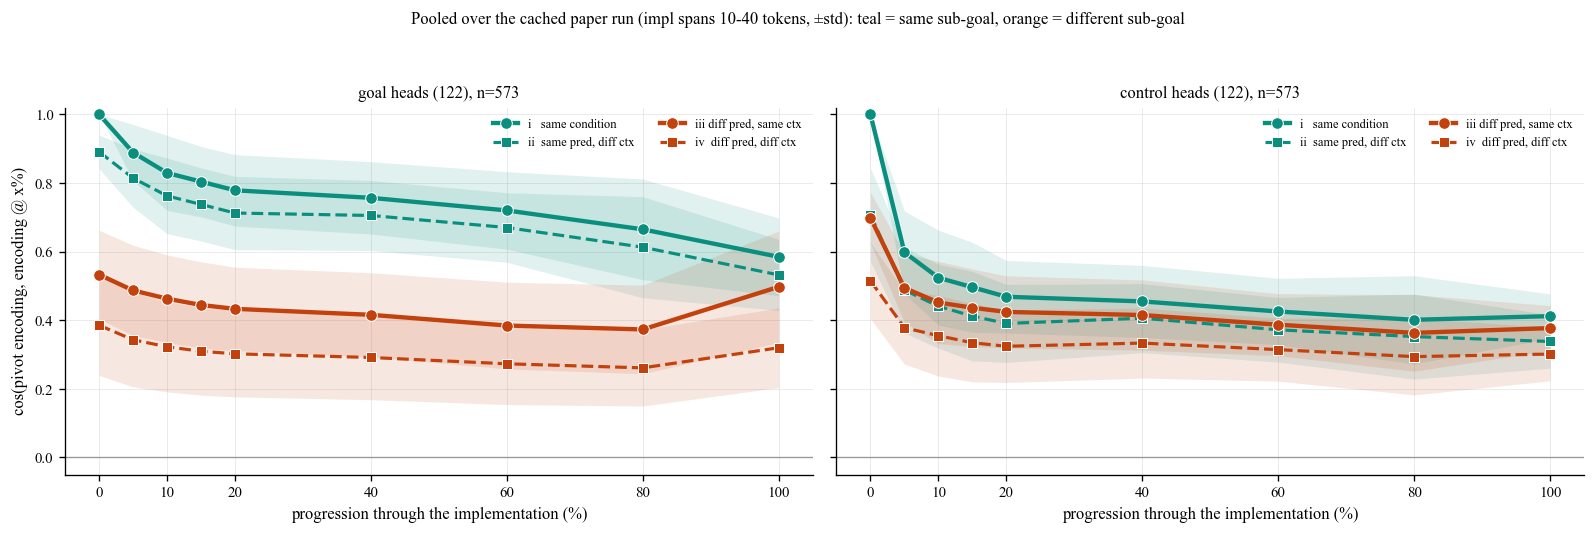

                                    cos(pivot, enc @ x%), pooled                                    
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┓
┃ heads   ┃ comparison              ┃   0% ┃   5% ┃  10% ┃  15% ┃  20% ┃  40% ┃  60% ┃  80% ┃ 100% ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━┩
│ goal    │ i   same condition      │ 1.00 │ 0.89 │ 0.83 │ 0.80 │ 0.78 │ 0.76 │ 0.72 │ 0.66 │ 0.58 │
│ goal    │ ii  same pred, diff ctx │ 0.89 │ 0.81 │ 0.76 │ 0.74 │ 0.71 │ 0.71 │ 0.67 │ 0.61 │ 0.53 │
│ goal    │ iii diff pred, same ctx │ 0.53 │ 0.49 │ 0.46 │ 0.44 │ 0.43 │ 0.42 │ 0.38 │ 0.37 │ 0.50 │
│ goal    │ iv  diff pred, diff ctx │ 0.39 │ 0.34 │ 0.32 │ 0.31 │ 0.30 │ 0.29 │ 0.27 │ 0.26 │ 0.32 │
│ control │ i   same condition      │ 1.00 │ 0.60 │ 0.52 │ 0.50 │ 0.47 │ 0.45 │ 0.43 │ 0.40 │ 0.41 │
│ control │ ii  same pred, diff ctx │ 0.71 │ 0.49 │ 0.44 │ 0.41 │ 0.39 │ 0.41 │ 0.37 │ 0.35 │ 0.34 │
│ control │ iii diff pred, same ctx │ 0.70 │ 0.49 │ 0.45 │ 0.44 │ 0.42 │ 0.42 │ 0.39 │ 0.36 │ 0.38 │
│ control │ iv  diff pred, diff ctx │ 0.52 │ 0.38 │ 0.35 │ 0.33 │ 0.32 │ 0.33 │ 0.31 │ 0.29 │ 0.30 │
└─────────┴─────────────────────────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┘

In [9]:
SPAN, GRID = (10, 40), [0.0, 0.05, 0.10, 0.15, 0.2, 0.4, 0.6, 0.8, 1.0]
ctrl_recs = [torch.load(p)['record'] for p in glob.glob(os.path.join(cdir, 'control', 'cond_*.pt'))]
goal_recs = []
for r in ctrl_recs:   # the matched goal record of each control condition (same cache key, head_tag 'goal')
    p = os.path.join(cdir, f"cond_{TP._cond_key(SLUG, TP.HEAD_BUDGET, r['datatype'], r['pred_id'], r['lang'], r['ctx_key'], TP.MAX_NEW)}.pt")
    if os.path.exists(p):
        goal_recs.append(torch.load(p)['record'])
inspan = lambda R: [r for r in R if r['n_impl'] >= TP.MIN_IMPL and SPAN[0] <= r['n_impl'] <= SPAN[1]]
gk = {(r['datatype'], r['lang'], r['pred_id'], r['ctx_key'], r['pos']) for r in goal_recs}
goal_m = inspan(goal_recs)
ctrl_m = inspan([r for r in ctrl_recs if (r['datatype'], r['lang'], r['pred_id'], r['ctx_key'], r['pos']) in gk])
panels = [(f'goal heads (122), n={len(goal_m)}', TP.compute_curves(goal_m, GRID)),
          (f'control heads (122), n={len(ctrl_m)}', TP.compute_curves(ctrl_m, GRID))]
T_, O_ = F.TP_TEAL, F.TP_ORANGE
STYLE = {'i   same condition': (T_, '-', 'o', 2.6, 7), 'ii  same pred, diff ctx': (T_, '--', 's', 1.9, 6),
         'iii diff pred, same ctx': (O_, '-', 'o', 2.6, 7), 'iv  diff pred, diff ctx': (O_, '--', 's', 1.9, 6)}
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.5), sharey=True)
xs_ = [p * 100 for p in GRID]
for ax, (title, cur_set) in zip(axes, panels):
    for name, cur in cur_set.items():
        color, ls, mk, lw, ms = STYLE[name]
        mu = np.array([cur[p]['mean'] for p in GRID]); sd = np.array([cur[p]['std'] for p in GRID])
        ax.plot(xs_, mu, ls=ls, marker=mk, color=color, lw=lw, markersize=ms, markeredgecolor='white',
                markeredgewidth=.6, label=name, zorder=3)
        ax.fill_between(xs_, mu - sd, mu + sd, color=color, alpha=.12, lw=0, zorder=1)
    ax.axhline(0, color='#999', lw=.8); ax.set_ylim(top=1.02); ax.set_xticks([0, 10, 20, 40, 60, 80, 100])
    ax.set_xlabel('progression through the implementation (%)'); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7.5, ncol=2, frameon=False, loc='upper right')
axes[0].set_ylabel('cos(pivot encoding, encoding @ x%)')
fig.suptitle(f'Pooled over the cached paper run (impl spans {SPAN[0]}-{SPAN[1]} tokens, ±std): teal = same sub-goal, orange = different sub-goal', fontsize=10)
fig.tight_layout(rect=(0, 0, 1, .94)); plt.show()
t = Table(title='cos(pivot, enc @ x%), pooled')
t.add_column('heads'); t.add_column('comparison'); [t.add_column(f'{p*100:g}%', justify='right') for p in GRID]
for title, cur_set in panels:
    for name, cur in cur_set.items():
        t.add_row(title.split(' heads')[0], name, *[f"{cur[p]['mean']:.2f}" for p in GRID])
console.print(t)
del ctrl_recs, goal_recs

The four relation masks of `TP.compute_curves`: **i** compares a condition with itself, **ii** compares the same
sub-task in a different context (other function, possibly the other language), **iii** compares a different sub-task in
the same function, and **iv** compares a different sub-task in a different context. In the goal-head panel the teal
curves (same sub-goal) stay well above the orange ones (different sub-goal) through the whole implementation, and
**ii** stays high too, so the encoding names the sub-goal and not the particular function. Control heads have a
high **i** at 0% (any vector matches itself), but they lose most of the separation within the first few tokens of the
implementation.

# Part B: obstacle persistence

## 5. A forced bad start
`build_obstacle_prompt` makes a two-sub-task function (`a` prefilled, target `b`) and appends an obstacle prefix after
`b =` that the model cannot delete. The prefixes come in three levels (`obstacle_persistence_prefills.py`):
- **aligned**: a correct start of the sub-goal (ceiling control);
- **easy**: ignorable stubs such as `0 +` or `(`;
- **hard**: a wrong sibling predicate in an escapable `((...)` form, or a wrong-op fragment like `- 1 +`.

Every obstacle leaves a syntactic way out. The model greedily continues the line (48 tokens) and `judge_adapts`
(Claude) decides whether it still implements the sub-goal *while adapting to* the prefix. No goal heads are
involved: this is the behavioural side of persistence.

In [10]:
from scripts.evaluation.obstacle_persistence_eval import build_obstacle_prompt, run_obstacle, LEVELS, N_PER
from scripts.evaluation.obstacle_persistence_prefills import OBSTACLE_PREFILLS
from scripts.evaluation.obstacle_persistence_judge import judge_adapts

HARD = ' - 1 +'
ob_prompt, target = build_obstacle_prompt(mt, OBST_DT, OBST_PID, HARD)
print(f'target sub-goal b: "{target.description}"   obstacle: {HARD!r}\n')
print(ob_prompt)

target sub-goal b: "the sum of all values"   obstacle: ' - 1 +'

<|im_start|>system
You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just the code, no need to comment or explain.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `func` which, given a list of integers `nums`, computes:
(1) the number of positive values
(2) the sum of all values
<|im_end|>
<|im_start|>assistant
<code>
def func(nums: list[int]):
    a = sum(1 for x in nums if x > 0)
    b = - 1 +


In [11]:
rhs, _ = run_obstacle(mt, OBST_DT, OBST_PID, HARD)
v = judge_adapts(target.description, HARD, rhs)
console.print(f'[dim]    b =[/dim][bold red]{escape(HARD)}[/bold red][bold green]{escape(rhs[len(HARD.strip()):])}[/bold green]')
col = 'green' if v['verdict'] == 'ADAPTED' else 'red'
console.print(f'judge: [{col}]{v["verdict"]}[/]  ({escape(v["rationale"])})')

    b = - 1 + sum(nums) + 1

judge: ADAPTED  (The expression `-1 + sum(nums) + 1` simplifies to `sum(nums)`, correctly computing the sum of all values while 
incorporating the forced prefix.)

## 6. All levels for this sub-task, next to the paper run
The eval runs the first `N_PER = 4` prefixes of each level for every (datatype, predicate): 409 trials per model. Here
are this predicate's trials. The verdict column is our judge call (cached on disk, so a reproduced generation costs no
API call). The last column is the reported verdict from `results/obstacle_robustness/<model>/rows.json`.

In [12]:
paper = {(r['level'], r['prefix']): r for r in json.load(open(f'results/obstacle_robustness/{SLUG}/rows.json'))
         if r['dt'] == OBST_DT and r['pid'] == OBST_PID}
spec = OBSTACLE_PREFILLS[OBST_DT][OBST_PID]
t = Table(title=f'{escape(OBST_DT)} / {OBST_PID}: "{target.description}"', show_lines=True)
t.add_column('level'); t.add_column('forced prefix'); t.add_column('model continuation (b = ...)', max_width=60)
t.add_column('verdict'); t.add_column('paper'); t.add_column('same text?')
vc = lambda s: f"[{'green' if s == 'ADAPTED' else 'red'}]{s}[/]"
for lvl in LEVELS:
    for prefix in spec[lvl][:N_PER]:
        rhs_, _ = run_obstacle(mt, OBST_DT, OBST_PID, prefix)
        vv = judge_adapts(target.description, prefix, rhs_)['verdict']
        pr = paper.get((lvl, prefix), {})
        t.add_row(lvl, escape(repr(prefix)), escape(rhs_), vc(vv), vc(pr.get('verdict', '-')), str(pr.get('rhs') == rhs_))
console.print(t)

                               list[int] / total_sum: "the sum of all values"                               
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ level   ┃ forced prefix   ┃ model continuation (b = ...)            ┃ verdict   ┃ paper     ┃ same text? ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ aligned │ ' sum(nums'     │ sum(nums)                               │ ADAPTED   │ ADAPTED   │ True       │
├─────────┼─────────────────┼─────────────────────────────────────────┼───────────┼───────────┼────────────┤
│ easy    │ ' 0 + '         │ 0 + 0j                                  │ SUCCUMBED │ SUCCUMBED │ True       │
├─────────┼─────────────────┼─────────────────────────────────────────┼───────────┼───────────┼────────────┤
│ easy    │ ' ('            │ (sum(nums))                             │ ADAPTED   │ ADAPTED   │ True       │
├─────────┼─────────────────┼─────────────────────────────────────────┼───────────┼───────────┼────────────┤
│ easy    │ ' (('           │ ((sum(nums),))                          │ BROKEN    │ BROKEN    │ True       │
├─────────┼─────────────────┼─────────────────────────────────────────┼───────────┼───────────┼────────────┤
│ hard    │ ' ((max(nums))' │ ((max(nums)) + (min(nums))) * len(nums) │ SUCCUMBED │ SUCCUMBED │ True       │
├─────────┼─────────────────┼─────────────────────────────────────────┼───────────┼───────────┼────────────┤
│ hard    │ ' - 1 +'        │ - 1 + sum(nums) + 1                     │ ADAPTED   │ ADAPTED   │ True       │
└─────────┴─────────────────┴─────────────────────────────────────────┴───────────┴───────────┴────────────┘

**The full result** (from the talk):

![Across models, LMs are not very good at recovering from obstacles (App. K.2).](figures/03_obstacle_models.png)

*Across models, LMs are not very good at recovering from obstacles (App. K.2).*

![The goal is still readable after the obstacle; the action is not (App. K.2, OV boost).](figures/03_obstacle_ov_boost.png)

*The goal is still readable after the obstacle; the action is not (App. K.2, OV boost).*

## Where this goes in the paper / how to reproduce at scale
- **Temporal persistence** (all contexts, 4 datatypes × {Python, C++}; writes `cond_*.pt` per condition):
  ```
  python scripts/evaluation/temporal_persistence_eval.py --cuda 0                          # goal heads
  python scripts/evaluation/temporal_persistence_eval.py --cuda 0 --control --n-trials 64  # control heads
  ```
  Cache: `results/temporal_persistence/Qwen2.5-Coder-32B-Instruct/{cond_*.pt, control/cond_*.pt}`; conditions already
  cached are skipped (use a scratch `RESULTS_DIR` in `env.yml` for a re-run). Figures:
  `notebooks/fig_n_table_generators/temporal_persistence.ipynb` (cell 3 = `fig:temporal-retention`, cell 2 =
  `fig:retention-control`, the panel recomputed above).
- **Obstacle persistence** (409 trials per model, 7 models):
  `python scripts/evaluation/obstacle_persistence_eval.py --cuda 0 [--model <id>]` →
  `results/obstacle_robustness/<model>/{trial_*.json, rows.json, summary.json}`. Paper ADAPTED rate
  (aligned / easy / hard), Coder-32B: .97 / .63 / .15 (`tab:obstacle-models`, generator
  `obstacle_persistence.ipynb`). The OV-boost variant (`tab:obstacle-ov-boost`) is
  `scripts/evaluation/obstacle_persistence_ov_boost_eval.py`.
- Previous: Demo 2 (GoalScope). Next: Demo 4 (are the goal heads necessary / sufficient?).